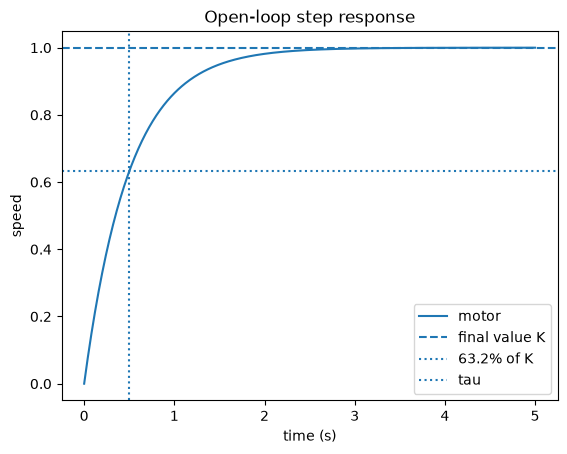

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct

K, tau = 1, 0.5                      # motor gain and time constant
G = ct.tf([K], [tau, 1])             # transfer function K / (tau*s + 1)

t = np.linspace(0, 5, 500)           # 500 time points from 0 to 5 s
t, y = ct.step_response(G, t)        # response to a step input

plt.plot(t, y, label="motor")
plt.axhline(K, ls="--", label="final value K")
plt.axhline(0.632 * K, ls=":", label="63.2% of K")
plt.axvline(tau, ls=":", label="tau")
plt.xlabel("time (s)"); plt.ylabel("speed")
plt.title("Open-loop step response"); plt.legend(); plt.show()

In [2]:
def make_pid(Kp, Ki=0.0, Kd=0.0):
    C = ct.tf([Kp], [1])
    if Ki != 0:
        C = C + ct.tf([Ki], [1, 0])     # integral term Ki/s
    if Kd != 0:
        C = C + ct.tf([Kd, 0], [1])     # derivative term Kd*s
    return C

In [3]:
%%writefile ../src/metrics.py
import numpy as np

def step_metrics(t, y, setpoint=1.0):
    t = np.asarray(t)
    y = np.asarray(y)
    y_final = y[-1]                                   # value the response settles to

    overshoot = max(0.0, (y.max() - y_final) / abs(y_final) * 100)

    i10 = np.argmax(y >= 0.1 * y_final)               # first index above 10%
    i90 = np.argmax(y >= 0.9 * y_final)               # first index above 90%
    rise_time = t[i90] - t[i10]

    outside = np.where(np.abs(y - y_final) > 0.02 * abs(y_final))[0]
    if len(outside) == 0:
        settling_time = 0.0
    elif outside[-1] == len(t) - 1:
        settling_time = np.nan                        # never settled in this window
    else:
        settling_time = t[outside[-1] + 1]            # last time outside the 2% band

    return {"overshoot": overshoot,
            "rise_time": rise_time,
            "settling_time": settling_time,
            "sse": setpoint - y_final}                # steady-state error

Overwriting ../src/metrics.py


In [4]:
import sys
sys.path.append("../src")
from metrics import step_metrics

In [5]:
T = ct.feedback(make_pid(5, 50, 0) * G, 1)
t = np.linspace(0, 10, 2000)
t, y = ct.step_response(T, t)

mine = step_metrics(t, y)
ref = ct.step_info(T, T=t)

print("overshoot   mine:", round(mine["overshoot"], 2), " library:", round(ref["Overshoot"], 2))
print("rise time   mine:", round(mine["rise_time"], 3), " library:", round(ref["RiseTime"], 3))
print("settling    mine:", round(mine["settling_time"], 3), " library:", round(ref["SettlingTime"], 3))

overshoot   mine: 19.45  library: 19.45
rise time   mine: 0.105  library: 0.105
settling    mine: 0.49  library: 0.49


In [6]:
def plot_cases(cases, title, filename, t_end=5):
    t = np.linspace(0, t_end, 1000)
    plt.figure(figsize=(8, 4.5))
    for Kp, Ki, Kd in cases:
        T = ct.feedback(make_pid(Kp, Ki, Kd) * G, 1)
        t, y = ct.step_response(T, t)
        m = step_metrics(t, y)
        plt.plot(t, y, label=f"Kp={Kp}, Ki={Ki}, Kd={Kd} | "
                             f"OS {m['overshoot']:.1f}%, ts {m['settling_time']:.2f}s, "
                             f"sse {m['sse']:.3f}")
    plt.axhline(1, ls="--", color="k", label="setpoint")
    plt.xlabel("time (s)")
    plt.ylabel("motor speed (normalized)")
    plt.title(title)
    plt.legend(loc="lower right", fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.savefig(f"../plots/{filename}", dpi=150)
    plt.show()

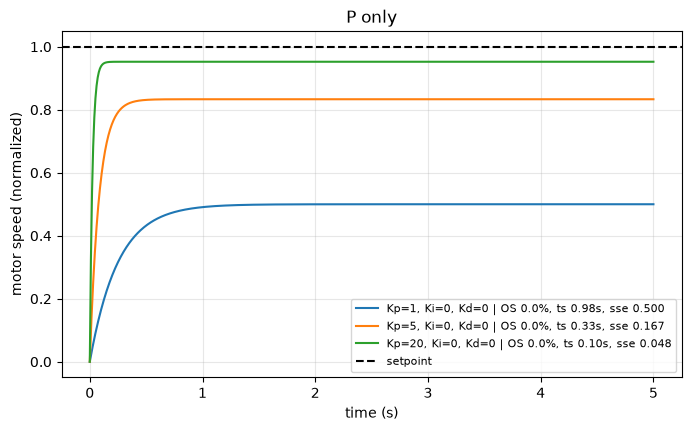

In [7]:
plot_cases([(1, 0, 0), (5, 0, 0), (20, 0, 0)], "P only", "p_only.png")

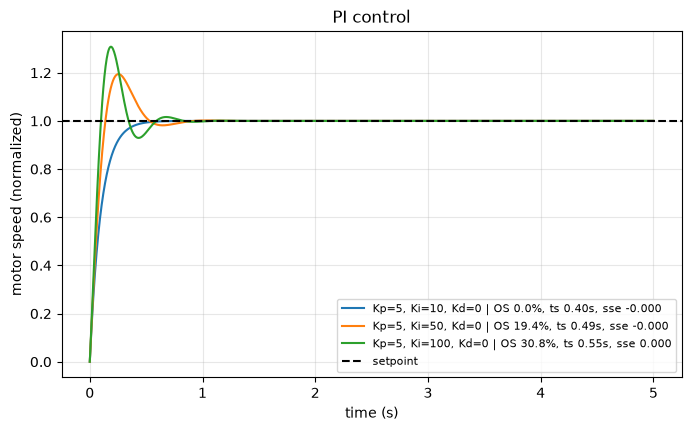

In [8]:
plot_cases([(5, 10, 0), (5, 50, 0), (5, 100, 0)], "PI control", "pi.png")

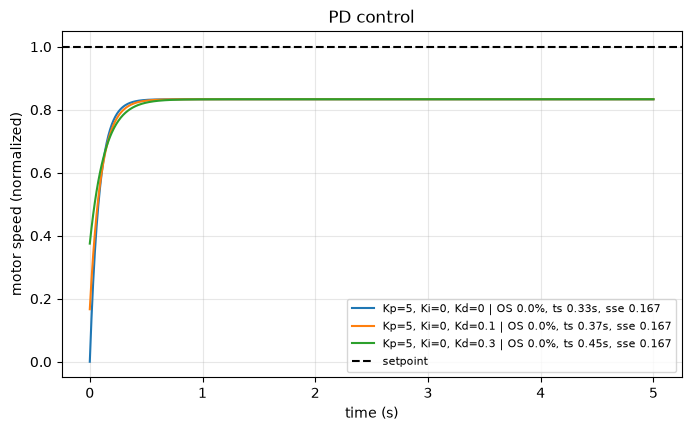

In [9]:
plot_cases([(5, 0, 0), (5, 0, 0.1), (5, 0, 0.3)], "PD control", "pd.png")

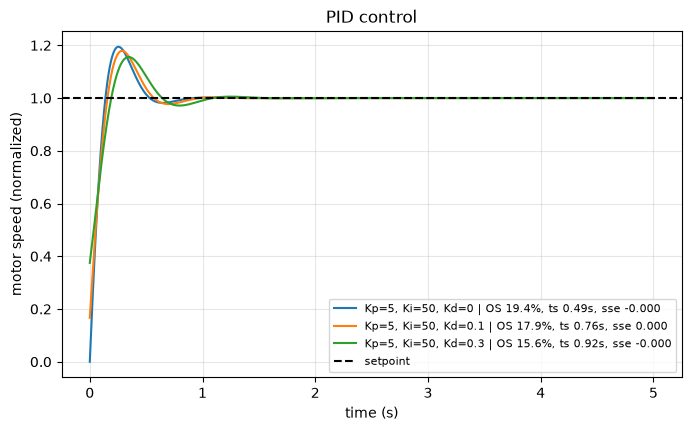

In [10]:
plot_cases([(5, 50, 0), (5, 50, 0.1), (5, 50, 0.3)], "PID control", "pid.png")

In [11]:
from ipywidgets import interact, FloatSlider

def explore(Kp=5.0, Ki=0.0, Kd=0.0):
    T = ct.feedback(make_pid(Kp, Ki, Kd) * G, 1)
    t = np.linspace(0, 5, 1000)
    t, y = ct.step_response(T, t)
    m = step_metrics(t, y)

    plt.figure(figsize=(8, 4))
    plt.plot(t, y, label="response")
    plt.axhline(1, ls="--", color="k", label="setpoint")
    plt.xlabel("time (s)"); plt.ylabel("motor speed (normalized)")
    plt.title(f"Kp={Kp}, Ki={Ki}, Kd={Kd}")
    plt.ylim(0, 2); plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    print(f"Overshoot: {m['overshoot']:.1f} %")
    print(f"Rise time: {m['rise_time']:.3f} s")
    print(f"Settling time: {m['settling_time']:.3f} s")
    print(f"Steady-state error: {m['sse']:.3f}")

interact(explore,
         Kp=FloatSlider(min=0.5, max=50, step=0.5, value=5),
         Ki=FloatSlider(min=0, max=200, step=1, value=0),
         Kd=FloatSlider(min=0, max=2, step=0.05, value=0))

interactive(children=(FloatSlider(value=5.0, description='Kp', max=50.0, min=0.5, step=0.5), FloatSlider(value…

<function __main__.explore(Kp=5.0, Ki=0.0, Kd=0.0)>

In [12]:
cases = {"P": [(1,0,0), (5,0,0), (20,0,0)],
         "PI": [(5,10,0), (5,50,0), (5,100,0)],
         "PD": [(5,0,0), (5,0,0.1), (5,0,0.3)],
         "PID": [(5,50,0), (5,50,0.1), (5,50,0.3)]}
t = np.linspace(0, 10, 2000)
for name, group in cases.items():
    for Kp, Ki, Kd in group:
        T = ct.feedback(make_pid(Kp, Ki, Kd) * G, 1)
        t, y = ct.step_response(T, t)
        m = step_metrics(t, y)
        print(f"{name:3} Kp={Kp:<4} Ki={Ki:<4} Kd={Kd:<4} "
              f"OS={m['overshoot']:5.1f}%  rise={m['rise_time']:.3f}s  "
              f"settle={m['settling_time']:.3f}s  sse={m['sse']:.3f}")

P   Kp=1    Ki=0    Kd=0    OS=  0.0%  rise=0.550s  settle=0.980s  sse=0.500
P   Kp=5    Ki=0    Kd=0    OS=  0.0%  rise=0.185s  settle=0.330s  sse=0.167
P   Kp=20   Ki=0    Kd=0    OS=  0.0%  rise=0.050s  settle=0.095s  sse=0.048
PI  Kp=5    Ki=10   Kd=0    OS=  0.0%  rise=0.220s  settle=0.395s  sse=-0.000
PI  Kp=5    Ki=50   Kd=0    OS= 19.4%  rise=0.105s  settle=0.490s  sse=0.000
PI  Kp=5    Ki=100  Kd=0    OS= 30.8%  rise=0.080s  settle=0.550s  sse=0.000
PD  Kp=5    Ki=0    Kd=0    OS=  0.0%  rise=0.185s  settle=0.330s  sse=0.167
PD  Kp=5    Ki=0    Kd=0.1  OS=  0.0%  rise=0.210s  settle=0.370s  sse=0.167
PD  Kp=5    Ki=0    Kd=0.3  OS=  0.0%  rise=0.230s  settle=0.445s  sse=0.167
PID Kp=5    Ki=50   Kd=0    OS= 19.4%  rise=0.105s  settle=0.490s  sse=0.000
PID Kp=5    Ki=50   Kd=0.1  OS= 17.9%  rise=0.130s  settle=0.760s  sse=0.000
PID Kp=5    Ki=50   Kd=0.3  OS= 15.6%  rise=0.155s  settle=0.915s  sse=0.000


Kp: Raising Kp from 1 to 5 changed rise time from 0.550s to 0.185s and steady-state error from 0.500 to 0.167. Kp speeds up the response but a P-only controller never removes the error.
Ki: Raising Ki from 10 to 50 changed overshoot from 0.0% to 19.4% and settling time from 0.395s to 0.490s. Ki removes the steady-state error but builds overshoot.
Kd: Raising Kd from 0 to 0.3 in the PID case changed overshoot from 19.4% to 15.6%, rise time from 0.105 s to 0.155 s, and settling time from 0.490 s to 0.915 s. In the PD case, Kd left the steady-state error at 0.167 and slowed the response. Kd trims overshoot slightly but slows the response, because the ideal derivative term reacts to the step in the error.